# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities?
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Annie Nguyen, Sritha Alluri, Anh Bach

**Date:** 11/9/2026

# Question 1: Cleaning data and performing EDA & Visualization

Shape: (16814, 19)

First 5 rows:
 sale_date  sale_price  house_square_feet  attic_finished_square_feet  basement_square_feet  attached_garage_square_feet  detached_garage_square_feet  fireplaces       hvac_description     exterior interior  stories          roof_cover  year_built  bedrooms  bathrooms waterfront_type view_quality          utility_sewer
2020-01-02      380000               2157                           0                     0                          528                            0           0 Warm and Cool Air Zone Frame Siding  Drywall        2 Composition Shingle        1993         3          3             NaN          NaN SEWER/SEPTIC INSTALLED
2020-01-02      383000               2238                           0                     0                          396                            0           0             Forced Air Frame Siding  Drywall        2 Composition Shingle        2017         4          3             NaN          NaN SEWER/SEPTIC INSTALLED
202

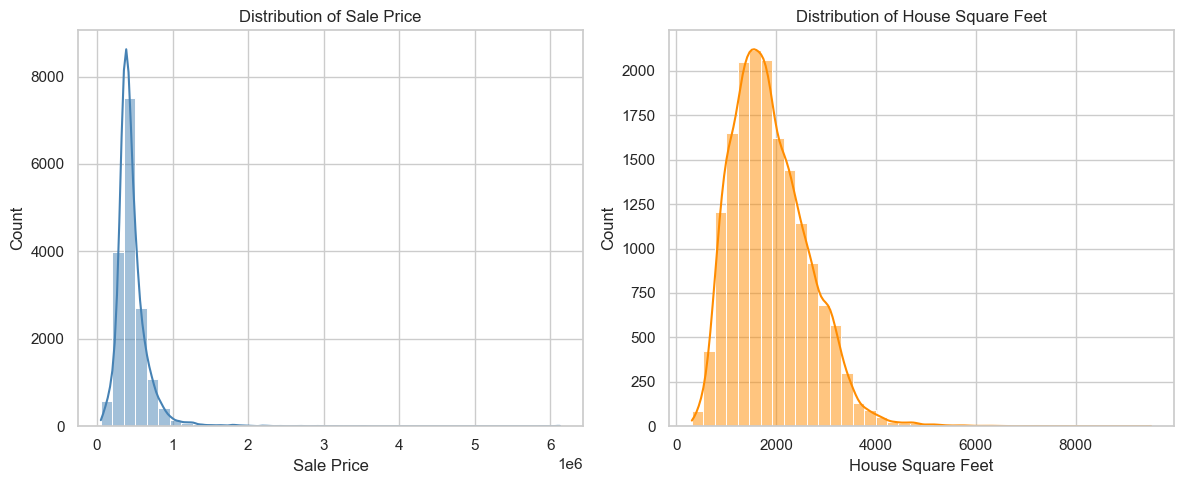

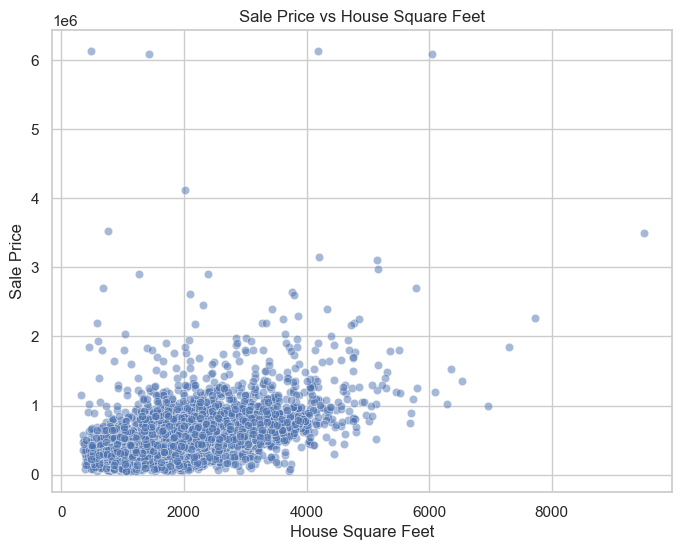

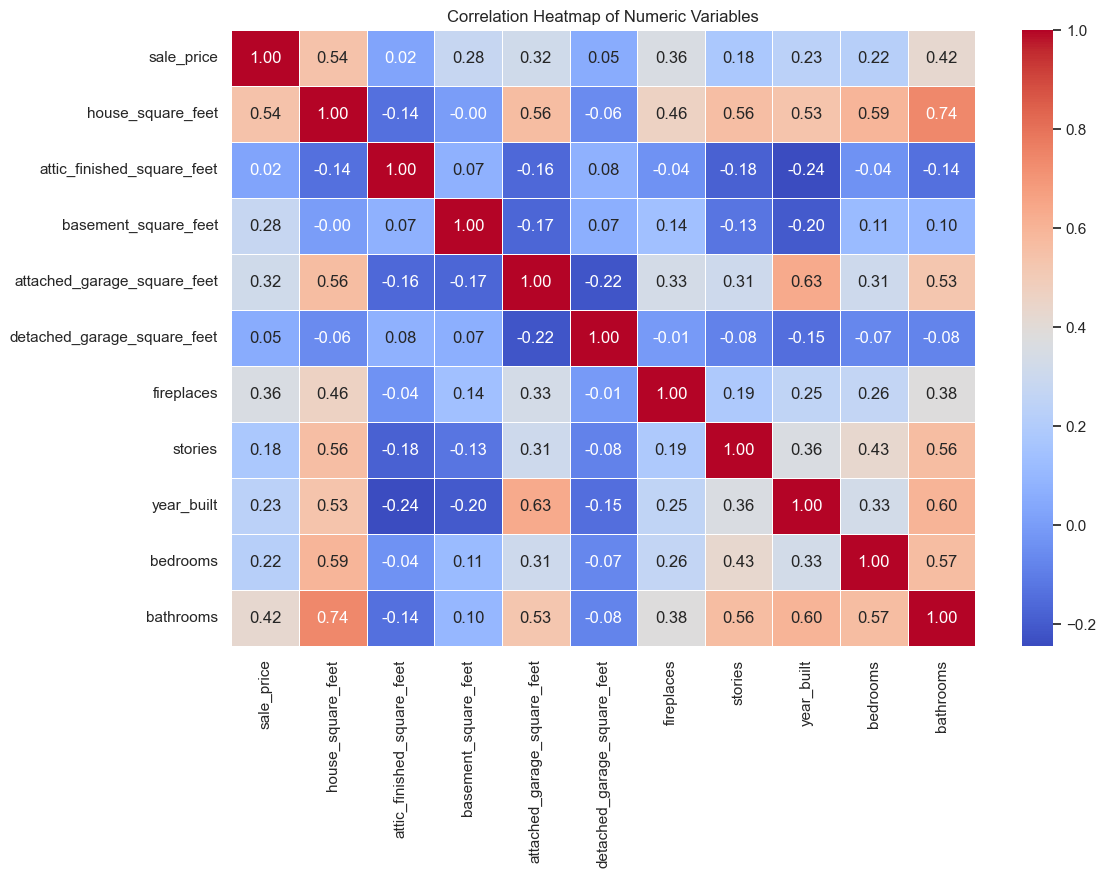

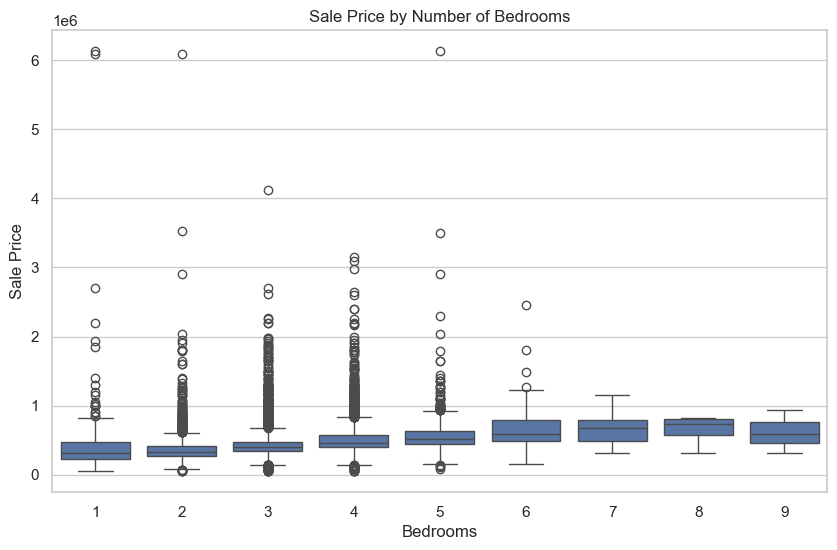

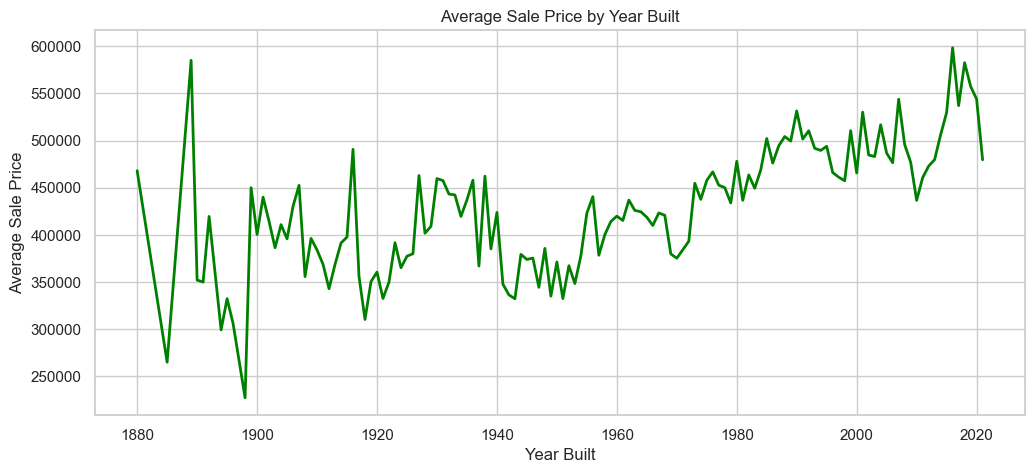

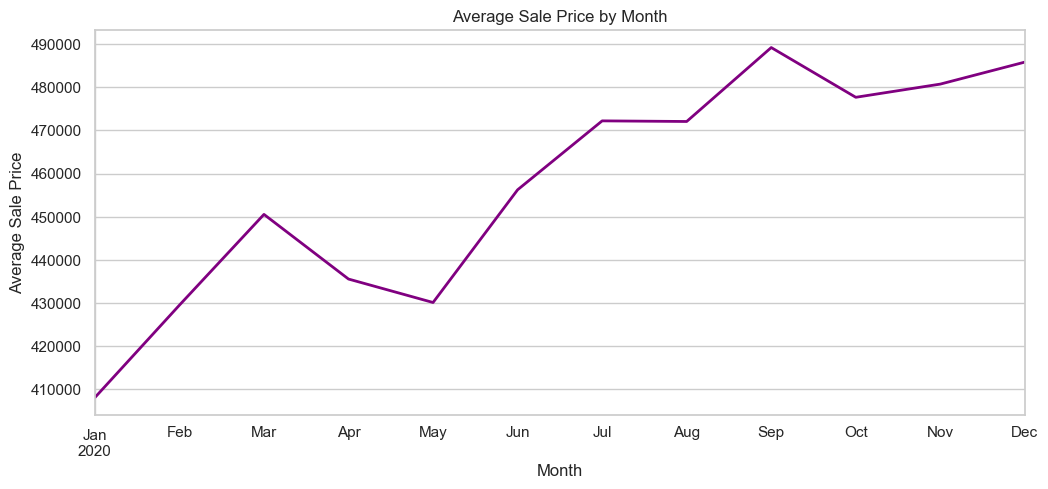


Top HVAC descriptions:
hvac_description
Forced Air                10306
Electric Baseboard         2627
Heat Pump                  2067
Warm and Cool Air Zone     1261
Floor/Wall Furnace          169
Hot Water Baseboard         146
No Heat                      63
Unknown                       3
Electric                      1
Floor Wall Furnace            1

Top exterior materials:
exterior
Frame Siding              14457
Frame Vinyl                1710
Masonry Common Brick        208
Frame Stucco                156
Masonry Concrete Block       42
Frame Rustic Log             21
Finished Cottage             20
Frame Hardboard              11
Log                          11
Cedar Finished Cabin          4

Outlier count in sale_price: 971


,sale_date,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,hvac_description,exterior,interior,stories,roof_cover,year_built,bedrooms,bathrooms,waterfront_type,view_quality,utility_sewer
0,2020-01-02,380000,2157,0,0,528,0,0,Warm and Cool Air Zone,Frame Siding,Drywall,2,Composition Shingle,1993,3,3,None,None,SEWER/SEPTIC INSTALLED
1,2020-01-02,383000,2238,0,0,396,0,0,Forced Air,Frame Siding,Drywall,2,Composition Shingle,2017,4,3,None,None,SEWER/SEPTIC INSTALLED
2,2020-01-01,419900,1452,0,0,0,0,1,Forced Air,Frame Siding,Drywall,1,Built Up Rock,1965,3,2,None,None,SEWER/SEPTIC INSTALLED
3,2020-01-02,251660,832,0,0,0,0,0,Forced Air,Frame Vinyl,Drywall,1,Composition Shingle,1919,2,1,None,None,SEWER/SEPTIC INSTALLED
4,2020-01-02,500000,1780,0,384,484,0,1,Forced Air,Frame Siding,Drywall,1,Composition Shingle,1955,3,2,None,None,SEWER/SEPTIC INSTALLED


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset from the data folder
data_path = Path("data") / "pierce_county_house_sales.csv"
df = pd.read_csv(data_path)

print("Shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head().to_string(index=False))
print("\nMissing values before cleaning:")
print(df.isna().sum().sort_values(ascending=False).head(20).to_string())

df = df.copy()
df["sale_date"] = pd.to_datetime(df["sale_date"], errors="coerce")
df = df.drop_duplicates().reset_index(drop=True)

# Drop implausible or non-market records instead of keeping them.
rows_before = len(df)
df = df[
    (df["sale_price"] >= 50_000)
    & (df["house_square_feet"] >= 300)
    & (df["bedrooms"].between(1, 10))
    & (df["bathrooms"] >= 1)
    & (df["stories"] >= 1)
].reset_index(drop=True)
print(f"\nRows dropped as implausible: {rows_before - len(df)}")

# Missing waterfront / view means the house has none, not that the value is unknown, so labeling it "None"
df["waterfront_type"] = df["waterfront_type"].fillna("None")
df["view_quality"] = df["view_quality"].fillna("None")
# The few missing values in the other categoricals stay "Unknown"
for col in ["hvac_description", "exterior", "interior", "roof_cover", "utility_sewer"]:
    df[col] = df[col].fillna("Unknown")

print("\nMissing values after cleaning:")
print(df.isna().sum().sort_values(ascending=False).head(20).to_string())
print("\nNumeric summary:")
print(df.describe().T.to_string())

sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(df["sale_price"], bins=40, kde=True, color="steelblue")
plt.title("Distribution of Sale Price")
plt.xlabel("Sale Price")
plt.ylabel("Count")

plt.subplot(1, 2, 2)
sns.histplot(df["house_square_feet"], bins=40, kde=True, color="darkorange")
plt.title("Distribution of House Square Feet")
plt.xlabel("House Square Feet")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="house_square_feet", y="sale_price", alpha=0.5)
plt.title("Sale Price vs House Square Feet")
plt.xlabel("House Square Feet")
plt.ylabel("Sale Price")
plt.show()

numeric_df = df.select_dtypes(include=["number"])
corr = numeric_df.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap of Numeric Variables")
plt.show()

plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="bedrooms", y="sale_price")
plt.title("Sale Price by Number of Bedrooms")
plt.xlabel("Bedrooms")
plt.ylabel("Sale Price")
plt.show()

yearly_avg = df.groupby("year_built")["sale_price"].mean().sort_index()
plt.figure(figsize=(12, 5))
yearly_avg.plot(kind="line", linewidth=2, color="green")
plt.title("Average Sale Price by Year Built")
plt.xlabel("Year Built")
plt.ylabel("Average Sale Price")
plt.show()

monthly_avg = (
    df.assign(month=df["sale_date"].dt.to_period("M"))
      .groupby("month")["sale_price"]
      .mean()
)
plt.figure(figsize=(12, 5))
monthly_avg.plot(kind="line", linewidth=2, color="purple")
plt.title("Average Sale Price by Month")
plt.xlabel("Month")
plt.ylabel("Average Sale Price")
plt.show()

# Distribution of major categorical features
print("\nTop HVAC descriptions:")
print(df["hvac_description"].value_counts().head(10).to_string())

print("\nTop exterior materials:")
print(df["exterior"].value_counts().head(10).to_string())

# Outlier check for sale price
Q1 = df["sale_price"].quantile(0.25)
Q3 = df["sale_price"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df["sale_price"] < lower_bound) | (df["sale_price"] > upper_bound)]
print(f"\nOutlier count in sale_price: {len(outliers)}")
df.head()

After dropping 124 implausible records, 16,644 sales from 2020 remain. Sale price is strongly right-skewed, with a median of about 417K dollars but a few homes selling for over 1M, up to 6.1M. We keep these high-price outliers because they are real sales. Living area has the strongest correlation with price (0.54), followed by bathrooms and fireplaces. Newer homes sell for more, and prices rose through 2020. Waterfront and view homes are rare but sell for large premiums, around 800K to 915K dollars for lake or salt-water frontage vs. 415K with none.

# Question 2: Transforming Variables

In [ ]:
# Make numeric features from the sale date
df["sale_month"] = df["sale_date"].dt.month

# Merging the same categories
df["hvac_description"] = df["hvac_description"].replace({"Floor Wall Furnace": "Floor/Wall Furnace"})
# Some dummies had only 0-2 homes in the training set, which gives unreliable coefficients
for col in ["hvac_description", "exterior", "interior", "roof_cover", "utility_sewer"]:
    counts = df[col].value_counts()
    df[col] = df[col].replace(dict.fromkeys(counts[counts < 30].index, "Other"))

# Separate the target (what we want to predict) from the predictors
y = df["sale_price"]
X = df.drop(columns=["sale_price", "sale_date"])

# Convert categorical variables into numeric indicator columns.
categorical_cols = X.select_dtypes(include=["object", "string", "category"]).columns

X = pd.get_dummies(
    X,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

print("Predictor matrix shape:", X.shape)
print("Target shape:", y.shape)
print("\nAll predictor columns are numeric:", X.select_dtypes(exclude="number").empty)
print("\nFirst five rows of transformed predictors:")
display(X.head())

Predictor matrix shape: (16644, 43)
Target shape: (16644,)

All predictor columns are numeric: True

First five rows of transformed predictors:


,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,stories,year_built,bedrooms,bathrooms,...,waterfront_type_WF Stream/Creek,view_quality_View Avg,view_quality_View Avg +,view_quality_View Good,view_quality_View Good +,view_quality_View Lim,view_quality_View Lim +,view_quality_View Lim -,view_quality_View V-Good,utility_sewer_SEWER/SEPTIC INSTALLED
0,2157,0,0,528,0,0,2,1993,3,3,...,0,0,0,0,0,0,0,0,0,1
1,2238,0,0,396,0,0,2,2017,4,3,...,0,0,0,0,0,0,0,0,0,1
2,1452,0,0,0,0,1,1,1965,3,2,...,0,0,0,0,0,0,0,0,0,1
3,832,0,0,0,0,0,1,1919,2,1,...,0,0,0,0,0,0,0,0,0,1
4,1780,0,384,484,0,1,1,1955,3,2,...,0,0,0,0,0,0,0,0,0,1


# Question 3: Implement an 80/20 train-test split

In [ ]:
from sklearn.model_selection import train_test_split

# Split predictors and target into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training predictors:", X_train.shape)
print("Test predictors:", X_test.shape)
print("Training target:", y_train.shape)
print("Test target:", y_test.shape)

Training predictors: (13315, 43)
Test predictors: (3329, 43)
Training target: (13315,)
Test target: (3329,)


# Question 4: Fit and compare simple linear models
The model with all predictors did best, with a test RMSE of \$159,389 and test R^2 of 0.545. Training and test results are close for every model, so none of them is overfitting, but even the best leaves about 45% of the variation in price unexplained.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import pandas as pd

numeric_features = [
    "house_square_feet",
    "attic_finished_square_feet",
    "basement_square_feet",
    "attached_garage_square_feet",
    "detached_garage_square_feet",
    "fireplaces",
    "stories",
    "year_built",
    "bedrooms",
    "bathrooms",
    "sale_month",
]

numeric_features = [col for col in numeric_features if col in X_train.columns]

model_features = {
    "House size only": ["house_square_feet"],
    "Core features": [
        "house_square_feet",
        "bedrooms",
        "bathrooms",
        "year_built",
        "stories",
    ],
    "All numeric features": numeric_features,
    "All predictors (including categories)": list(X_train.columns),
}

results = []

for model_name, features in model_features.items():
    features = [col for col in features if col in X_train.columns]

    model = LinearRegression()
    model.fit(X_train[features], y_train)

    train_predictions = model.predict(X_train[features])
    test_predictions = model.predict(X_test[features])

    results.append({
        "Model": model_name,
        "Number of predictors": len(features),
        "Train RMSE": np.sqrt(mean_squared_error(y_train, train_predictions)),
        "Train R²": r2_score(y_train, train_predictions),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, test_predictions)),
        "Test R²": r2_score(y_test, test_predictions),
    })

results_df = pd.DataFrame(results).sort_values("Test RMSE")
display(results_df.round(3))

,Model,Number of predictors,Train RMSE,Train R²,Test RMSE,Test R²
3,All predictors (including categories),43,152243.254,0.563,159388.818,0.545
2,All numeric features,11,172606.059,0.438,180557.740,0.416
1,Core features,5,186026.949,0.347,191764.162,0.341
0,House size only,1,193793.719,0.291,198240.046,0.296


# Question 5: Partial correlation plots
Most relationships are close to linear, with a few clear exceptions. Year built is U-shaped: both the oldest and the newest homes sell for more than mid-century ones. Basement and detached garage jump at zero, so having one matters separately from its size. Square footage flattens slightly for very large homes. Sale month is flat early in 2020 and rises from mid-year.

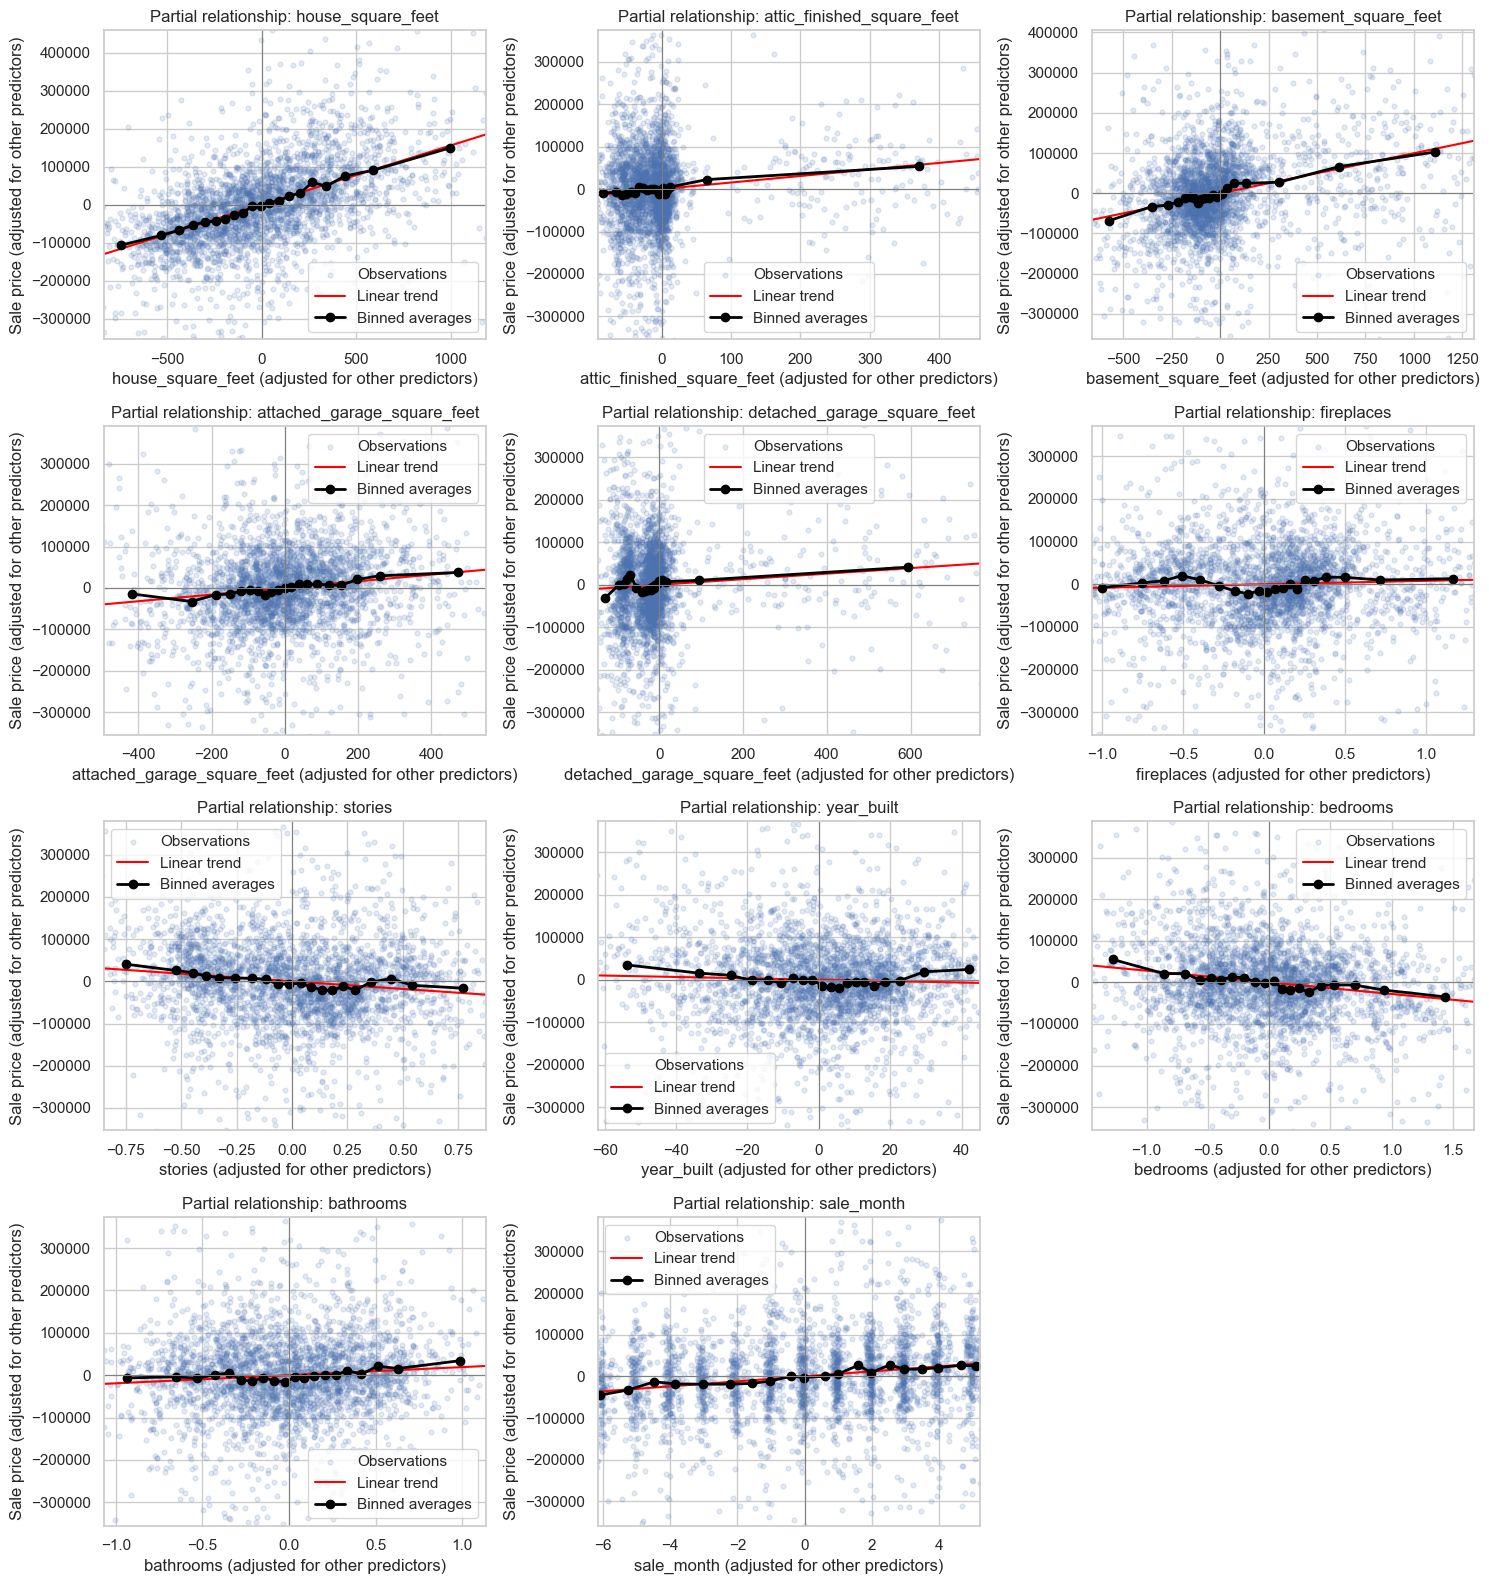

In [ ]:
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import math

numeric_features = [
    "house_square_feet",
    "attic_finished_square_feet",
    "basement_square_feet",
    "attached_garage_square_feet",
    "detached_garage_square_feet",
    "fireplaces",
    "stories",
    "year_built",
    "bedrooms",
    "bathrooms",
    "sale_month",
]

numeric_features = [col for col in numeric_features if col in X_train.columns]
all_features = list(X_train.columns)

ncols = 3
nrows = math.ceil(len(numeric_features) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
axes = np.array(axes).reshape(-1)

for i, feature in enumerate(numeric_features):
    other_features = [col for col in all_features if col != feature]

    y_model = LinearRegression().fit(X_train[other_features], y_train)
    y_residual = y_train - y_model.predict(X_train[other_features])

    x_model = LinearRegression().fit(
        X_train[other_features],
        X_train[feature]
    )
    x_residual = X_train[feature] - x_model.predict(X_train[other_features])

    partial_data = pd.DataFrame({
        "x_residual": np.asarray(x_residual),
        "y_residual": np.asarray(y_residual),
    })

    points = partial_data.sample(
        n=min(3000, len(partial_data)),
        random_state=42
    )
    axes[i].scatter(
        points["x_residual"],
        points["y_residual"],
        alpha=0.15,
        s=12,
        label="Observations"
    )

    x_values = partial_data["x_residual"].to_numpy(dtype=float)
    y_values = partial_data["y_residual"].to_numpy(dtype=float)
    valid = np.isfinite(x_values) & np.isfinite(y_values)
    x_values = x_values[valid]
    y_values = y_values[valid]

    x_scale = max(1.0, np.max(np.abs(x_values))) if len(x_values) else 1.0
    has_variation = (
        len(x_values) > 1
        and np.ptp(x_values) > np.finfo(float).eps * x_scale
    )

    if has_variation:
        slope, intercept = np.polyfit(x_values, y_values, 1)
        x_line = np.linspace(x_values.min(), x_values.max(), 100)
        axes[i].plot(
            x_line,
            slope * x_line + intercept,
            color="red",
            label="Linear trend"
        )

        plot_data = pd.DataFrame({
            "x_residual": x_values,
            "y_residual": y_values
        })
        plot_data["bin"] = pd.qcut(
            plot_data["x_residual"],
            q=20,
            duplicates="drop"
        )
        binned = plot_data.groupby("bin", observed=True).agg(
            x_mean=("x_residual", "mean"),
            y_mean=("y_residual", "mean")
        )
        axes[i].plot(
            binned["x_mean"],
            binned["y_mean"],
            color="black",
            marker="o",
            linewidth=2,
            label="Binned averages"
        )
    else:
        axes[i].text(
            0.5,
            0.95,
            "No variation in adjusted predictor",
            transform=axes[i].transAxes,
            ha="center",
            va="top"
        )
    # Zoom each plot to the middle 98% of points
    if has_variation:
        axes[i].set_xlim(np.percentile(x_values, [1, 99]))
        axes[i].set_ylim(np.percentile(y_values, [1, 99]))

    axes[i].axhline(0, color="gray", linewidth=0.8)
    axes[i].axvline(0, color="gray", linewidth=0.8)
    axes[i].set_title(f"Partial relationship: {feature}")
    axes[i].set_xlabel(f"{feature} (adjusted for other predictors)")
    axes[i].set_ylabel("Sale price (adjusted for other predictors)")
    if has_variation:
        axes[i].legend()

for i in range(len(numeric_features), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()

# Question 6: Build complex model and compare

In [ ]:
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, r2_score

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

view_cols = [c for c in X_train.columns if c.startswith("view_quality_")]
waterfront_cols = [c for c in X_train.columns if c.startswith("waterfront_type_")]

def add_features(X_in):
    Z = X_in.copy()
    # Floor size at 300 sq ft inside the new features
    sqft = Z["house_square_feet"].clip(lower=300)
    # Diminishing returns to size: use log of living area instead of raw square feet
    Z["log_sqft"] = np.log(sqft)
    Z["age"] = 2020 - Z["year_built"]  # every sale is in 2020
    Z["age_sq"] = Z["age"] ** 2
    # Having a basement / attic / garage at all is a step up, separate from its size
    Z["has_basement"] = (Z["basement_square_feet"] > 0).astype(int)
    Z["has_attic"] = (Z["attic_finished_square_feet"] > 0).astype(int)
    Z["has_att_garage"] = (Z["attached_garage_square_feet"] > 0).astype(int)
    Z["has_det_garage"] = (Z["detached_garage_square_feet"] > 0).astype(int)
    # For a given size, more bedrooms means smaller rooms
    Z["beds_per_1000sqft"] = Z["bedrooms"] / sqft * 1000
    # Interactions: views, waterfront, age and bathrooms matter more on bigger houses
    any_view = Z[view_cols].sum(axis=1)
    any_waterfront = Z[waterfront_cols].sum(axis=1)
    Z["log_sqft_x_view"] = Z["log_sqft"] * any_view
    Z["log_sqft_x_waterfront"] = Z["log_sqft"] * any_waterfront
    Z["age_x_log_sqft"] = Z["age"] * Z["log_sqft"]
    Z["baths_x_log_sqft"] = Z["bathrooms"] * Z["log_sqft"]
    # Replaced by log_sqft and age above
    return Z.drop(columns=["house_square_feet", "year_built"])

X_train_c = add_features(X_train)
X_test_c = add_features(X_test)

# Model log(price): features add a percentage to value, and the log evens out the skew
log_y_train = np.log(y_train)
complex_model = LinearRegression().fit(X_train_c, log_y_train)

smear = np.mean(np.exp(log_y_train - complex_model.predict(X_train_c)))
complex_train_pred = np.exp(complex_model.predict(X_train_c)) * smear
complex_test_pred = np.exp(complex_model.predict(X_test_c)) * smear

complex_row = {
    "Model": "Complex (log price, transforms, interactions)",
    "Number of predictors": X_train_c.shape[1],
    "Train RMSE": rmse(y_train, complex_train_pred),
    "Train R²": r2_score(y_train, complex_train_pred),
    "Test RMSE": rmse(y_test, complex_test_pred),
    "Test R²": r2_score(y_test, complex_test_pred),
}
comparison = pd.concat([results_df, pd.DataFrame([complex_row])]).sort_values("Test RMSE")
display(comparison.round(3))

,Model,Number of predictors,Train RMSE,Train R²,Test RMSE,Test R²
3,All predictors (including categories),43,152243.254,0.563,159388.818,0.545
0,"Complex (log price, transforms, interactions)",53,145483.500,0.601,159594.491,0.543
2,All numeric features,11,172606.059,0.438,180557.740,0.416
1,Core features,5,186026.949,0.347,191764.162,0.341
0,House size only,1,193793.719,0.291,198240.046,0.296


In [ ]:
# Dollar RMSE is dominated by a few very expensive sales, so also compare the typical percentage error on the test set
simple_model = LinearRegression().fit(X_train, y_train)
simple_test_pred = simple_model.predict(X_test)

def pct_errors(y_true, y_pred):
    err = np.abs(y_pred - y_true) / y_true
    return {"Median abs. % error": np.median(err),
            "Share within ±10%": np.mean(err <= 0.10),
            "Share within ±20%": np.mean(err <= 0.20)}

display(pd.DataFrame({
    "All predictors (Q4)": pct_errors(y_test, simple_test_pred),
    "Complex (Q6)": pct_errors(y_test, complex_test_pred),
}).T.round(3))

# 5-fold cross-validation on the training set: is the difference consistent?
cv_rows = []
for fold, (tr, va) in enumerate(KFold(5, shuffle=True, random_state=42).split(X_train), start=1):
    m_simple = LinearRegression().fit(X_train.iloc[tr], y_train.iloc[tr])
    m_complex = LinearRegression().fit(X_train_c.iloc[tr], log_y_train.iloc[tr])
    s = np.mean(np.exp(log_y_train.iloc[tr] - m_complex.predict(X_train_c.iloc[tr])))
    cv_rows.append({
        "Fold": fold,
        "All predictors RMSE": rmse(y_train.iloc[va], m_simple.predict(X_train.iloc[va])),
        "Complex RMSE": rmse(y_train.iloc[va], np.exp(m_complex.predict(X_train_c.iloc[va])) * s),
    })
cv_df = pd.DataFrame(cv_rows).set_index("Fold")
cv_df.loc["Mean"] = cv_df.mean()
display(cv_df.round(0))

,Median abs. % error,Share within ±10%,Share within ±20%
All predictors (Q4),0.119,0.431,0.731
Complex (Q6),0.108,0.473,0.758


,All predictors RMSE,Complex RMSE
Fold,,
1,148034.0,140355.0
2,130832.0,127939.0
3,153579.0,145917.0
4,175388.0,174253.0
5,157971.0,144485.0
Mean,153161.0,146590.0


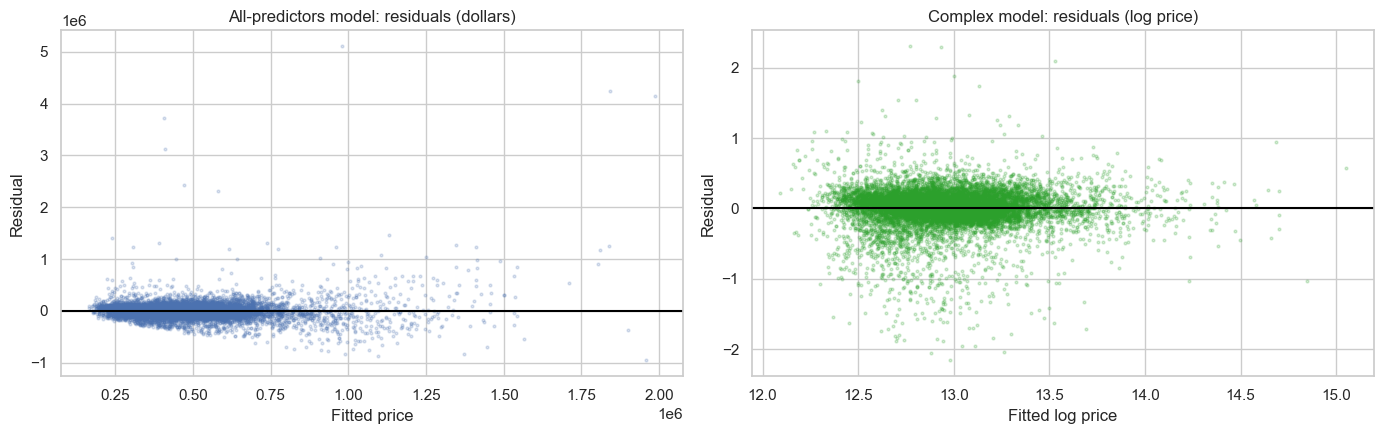

In [ ]:
# Residuals: the dollar model's errors fan out as price grows, the log model's should not
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
simple_fit = simple_model.predict(X_train)
axes[0].scatter(simple_fit, y_train - simple_fit, s=4, alpha=0.2)
axes[0].axhline(0, color="black")
axes[0].set(title="All-predictors model: residuals (dollars)", xlabel="Fitted price", ylabel="Residual")
log_fit = complex_model.predict(X_train_c)
axes[1].scatter(log_fit, log_y_train - log_fit, s=4, alpha=0.2, color="tab:green")
axes[1].axhline(0, color="black")
axes[1].set(title="Complex model: residuals (log price)", xlabel="Fitted log price", ylabel="Residual")
plt.tight_layout()
plt.show()

We built a more complex model that predicts the log of sale price, since features tend to raise a home's value by a percentage rather than a fixed dollar amount. It uses the log of square footage (each extra square foot adds less in bigger homes), age and age squared (new and historic homes sell for more), flags for having a basement, attic or garage, bedrooms per 1,000 sq ft, and interactions between size and view, waterfront, age and bathrooms. It has a training RMSE of 145,484 dollars (R^2 = 0.601) and a test RMSE of 159,594 dollars (R^2 = 0.543). That is far better than the simpler models (test R^2 of 0.30 for size only, 0.34 for core features and 0.42 for all numeric features), and about tied with the all-predictors model on the test set (159,389 dollars, R^2 = 0.545). The complex model's advantage shows up in cross-validation, where it had lower error in all 5 folds, and in percentage accuracy (10.8% vs. 11.9% median error). However, its larger gap between training and test error suggests it is starting to overfit.

# Question 7: Summary of Results

Across Questions 1–6, adding information steadily improved the models, with test R^2 rising from 0.30 with house size alone to 0.34 with core features, 0.42 with all numeric features, and 0.545 with all predictors including categories. Cleaning mattered too, since dropping 124 impossible or non-market records raised the all-predictors test R^2 from 0.522 to 0.545. The simple models underfit, since their training and test errors were both high and close together, which means they were missing structure rather than fitting noise. The complex model with log price, transformations and interactions fit the training data better (R^2 0.601) but only tied the all-predictors model on the test set (0.543), and its train–test gap doubled, an early sign of overfitting. The main lesson for model selection is that training performance always improves as you add features, so models have to be compared on held-out data. A single test split can also be misleading, because cross-validation showed a real advantage for the complex model that the one test set did not. Finally, about 45% of the variation in price stays unexplained, likely because the data has no location information, which would help more than further complexity.

# Question 8: Regularizing the model and selecting the most predictive features

In [ ]:
from sklearn.linear_model import Lasso, LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Scale features so the penalty is fair, pick alpha with 5-fold CV
lasso_cv = make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=42, max_iter=50_000))
lasso_cv.fit(X_train_c, log_y_train)
best_alpha = lasso_cv[-1].alpha_

# 1-SE rule: bigger alpha, fewer features, about the same CV error
cv_mse = lasso_cv[-1].mse_path_
mse_mean = cv_mse.mean(axis=1)
mse_se = cv_mse.std(axis=1) / np.sqrt(cv_mse.shape[1])
best_i = np.argmin(mse_mean)
alpha_1se = lasso_cv[-1].alphas_[mse_mean <= mse_mean[best_i] + mse_se[best_i]].max()

lasso_rows, lasso_coefs = [], {}
for label, alpha in [("Lasso (best CV alpha)", best_alpha), ("Lasso (1-SE alpha)", alpha_1se)]:
    lasso = make_pipeline(StandardScaler(), Lasso(alpha=alpha, max_iter=50_000)).fit(X_train_c, log_y_train)
    coefs = pd.Series(lasso[-1].coef_, index=X_train_c.columns)
    lasso_coefs[label] = coefs
    s = np.mean(np.exp(log_y_train - lasso.predict(X_train_c)))
    tr_pred = np.exp(lasso.predict(X_train_c)) * s
    te_pred = np.exp(lasso.predict(X_test_c)) * s
    lasso_rows.append({
        "Model": f"{label}, alpha = {alpha:.4f}",
        "Number of predictors": int((coefs != 0).sum()),
        "Train RMSE": rmse(y_train, tr_pred),
        "Train R²": r2_score(y_train, tr_pred),
        "Test RMSE": rmse(y_test, te_pred),
        "Test R²": r2_score(y_test, te_pred),
    })

all_models = pd.concat([comparison, pd.DataFrame(lasso_rows)]).sort_values("Test RMSE")
display(all_models.round(3))

# Features kept vs dropped
for label, coefs in lasso_coefs.items():
    kept = coefs[coefs != 0].sort_values(key=np.abs, ascending=False)
    print(f"\n{label}: keeps {len(kept)} of {len(coefs)} features")
    print("Dropped:", coefs[coefs == 0].index.tolist())

display(lasso_coefs["Lasso (1-SE alpha)"].loc[lambda c: c != 0]
        .sort_values(key=np.abs, ascending=False).round(4)
        .to_frame("Standardized coefficient (1-SE Lasso)"))

,Model,Number of predictors,Train RMSE,Train R²,Test RMSE,Test R²
3,All predictors (including categories),43,152243.254,0.563,159388.818,0.545
0,"Complex (log price, transforms, interactions)",53,145483.500,0.601,159594.491,0.543
0,"Lasso (best CV alpha), alpha = 0.0002",49,145957.605,0.598,160248.781,0.540
1,"Lasso (1-SE alpha), alpha = 0.0068",29,151505.478,0.567,162599.974,0.526
2,All numeric features,11,172606.059,0.438,180557.740,0.416
1,Core features,5,186026.949,0.347,191764.162,0.341
0,House size only,1,193793.719,0.291,198240.046,0.296



Lasso (best CV alpha): keeps 49 of 53 features
Dropped: ['bathrooms', 'exterior_Masonry Concrete Block', 'age', 'log_sqft_x_view']

Lasso (1-SE alpha): keeps 29 of 53 features
Dropped: ['bedrooms', 'bathrooms', 'hvac_description_Floor/Wall Furnace', 'hvac_description_Forced Air', 'hvac_description_Hot Water Baseboard', 'hvac_description_No Heat', 'exterior_Masonry Common Brick', 'exterior_Masonry Concrete Block', 'interior_Other', 'roof_cover_Formed Seam Metal', 'roof_cover_Other', 'roof_cover_Preformed Metal', 'roof_cover_Wood Shake', 'waterfront_type_WF River', 'waterfront_type_WF Stream/Creek', 'view_quality_View Avg', 'view_quality_View Good', 'view_quality_View Lim', 'view_quality_View Lim +', 'view_quality_View Lim -', 'utility_sewer_SEWER/SEPTIC INSTALLED', 'age', 'age_sq', 'has_det_garage']


,Standardized coefficient (1-SE Lasso)
log_sqft,0.1518
waterfront_type_WF Salt,0.0606
basement_square_feet,0.0496
attached_garage_square_feet,0.0480
baths_x_log_sqft,0.0407
waterfront_type_WF Lake,0.0397
log_sqft_x_view,0.0367
sale_month,0.0364
hvac_description_Heat Pump,0.0236
beds_per_1000sqft,-0.0221


The Lasso, applied to the complex model's standardized features with alpha chosen by 5-fold cross-validation (about 0.0002), keeps 49 of 53 features. It drops only bathrooms, age, Masonry Concrete Block exterior and the view × size interaction. It has a training RMSE of 145,958 dollars (R^2 = 0.598) and a test RMSE of 160,249 dollars (R^2 = 0.540), about the same as the complex model. A stronger alpha (about 0.0068, 1-SE rule) keeps only 29 features, led by log living area, salt-water and lake frontage, basement and garage size, bathrooms × size, view × size and sale month, with a test RMSE of 162,600 dollars (R^2 = 0.526). The Lasso didn't improve accuracy, but it gave a much simpler model that predicts almost as well.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [10b340574ae1a01028999dd81bfb0a395c2ee1da]
- **AI tool and model used:** [GPT-6]

### *Prompts used

1. [attached notebook and data] here is our notebook. highlight the parts that we made a mistake in or should change to better answer questions
2. should we change anything in our code or anything else

### *AI-proposed changes


1. Q6 and Q7 say the complex model is starting to overfit because its train-test gap is bigger than the all-predictors model's. Your own cross-validation doesn't support this. The complex model's CV RMSE of \$146,590 is about the same as its training RMSE of \$145,484, and it beat the all-predictors model in all 5 folds. That means it does about as well on new data as on training data, so the bigger gap on the test set is more likely because this particular split is harder. I'd remove the overfitting claim from both questions and say the complex model performs better.
2. Some of the most expensive sales show up as one sale split across two rows. For example, 6.13M dollars is listed for both a 480 sq ft house and a 4,188 sq ft house on the same date, and 6.09M dollars shows the same pattern. This looks like one property with more than one building, where each row got the full sale price. Since these rows can end up in both the training and test sets, they should be removed or flagged, and Q1 should mention this as a data issue instead of calling all high prices real sales.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | We refit both models on 20 random train/test splits. The complex model had lower test RMSE in 18 of the 20 and both models had about the same train-test gap. The bigger gap came from our split being a harder one, not from overfitting. We removed the overfitting sentence from Q6 and Q7. |
| 2 | Modify | We found the same problem with the sales. But 3,307 rows share a date and price with another row, and most of those are just different houses selling for the same round price on the same day. Most of the very expensive small homes are also real waterfront sales. Since we could not remove only the bad rows, we kept them and added a note in Q1. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

# Question 1: Cleaning data and performing EDA & Visualization

Shape: (16814, 19)

First 5 rows:
 sale_date  sale_price  house_square_feet  attic_finished_square_feet  basement_square_feet  attached_garage_square_feet  detached_garage_square_feet  fireplaces       hvac_description     exterior interior  stories          roof_cover  year_built  bedrooms  bathrooms waterfront_type view_quality          utility_sewer
2020-01-02      380000               2157                           0                     0                          528                            0           0 Warm and Cool Air Zone Frame Siding  Drywall        2 Composition Shingle        1993         3          3             NaN          NaN SEWER/SEPTIC INSTALLED
2020-01-02      383000               2238                           0                     0                          396                            0           0             Forced Air Frame Siding  Drywall        2 Composition Shingle        2017         4          3             NaN          NaN SEWER/SEPTIC INSTALLED
202

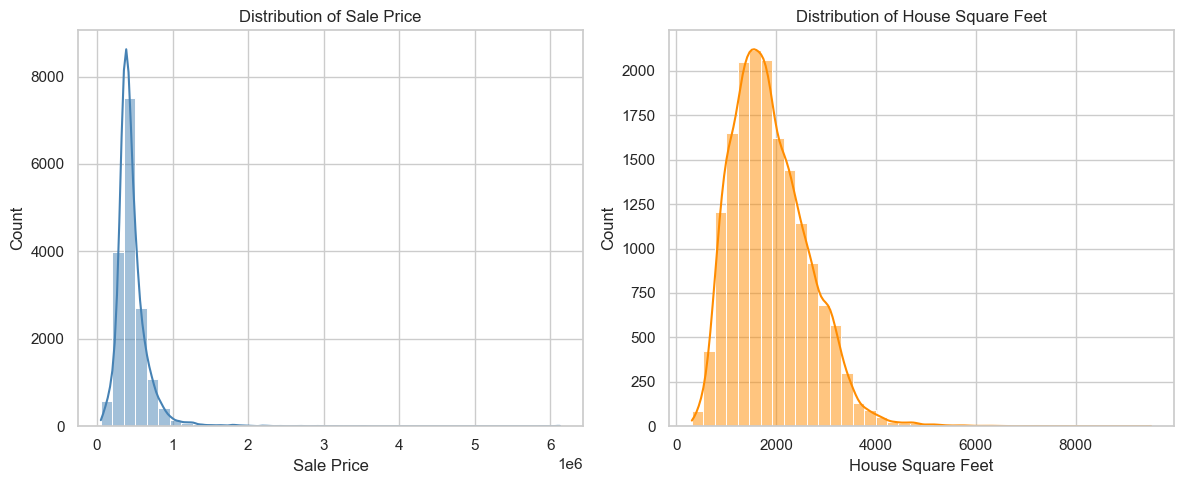

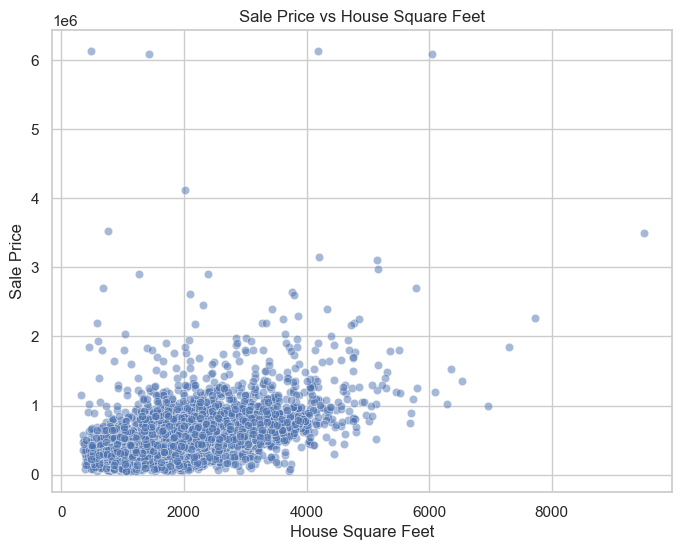

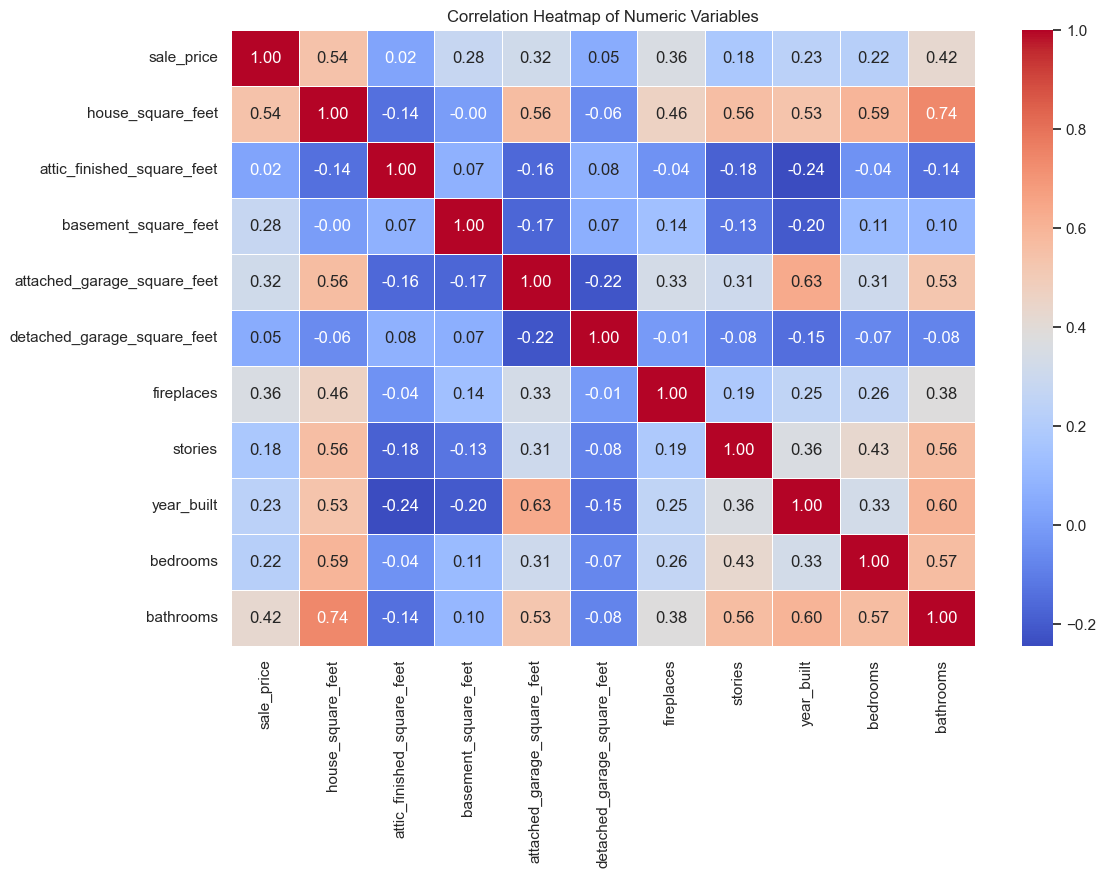

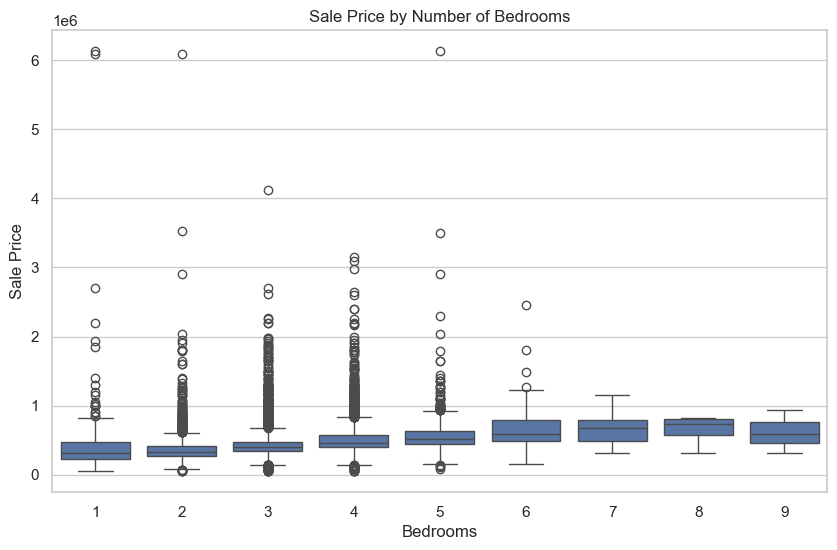

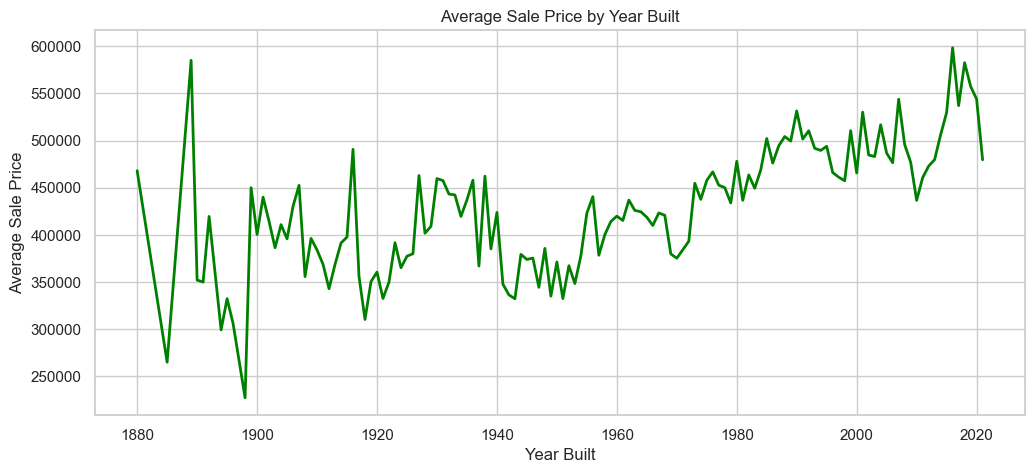

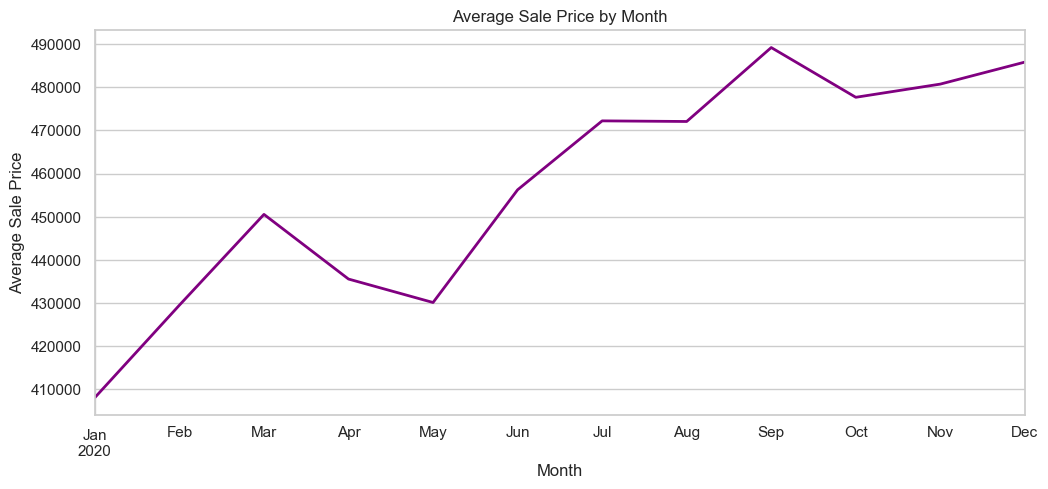


Top HVAC descriptions:
hvac_description
Forced Air                10306
Electric Baseboard         2627
Heat Pump                  2067
Warm and Cool Air Zone     1261
Floor/Wall Furnace          169
Hot Water Baseboard         146
No Heat                      63
Unknown                       3
Electric                      1
Floor Wall Furnace            1

Top exterior materials:
exterior
Frame Siding              14457
Frame Vinyl                1710
Masonry Common Brick        208
Frame Stucco                156
Masonry Concrete Block       42
Frame Rustic Log             21
Finished Cottage             20
Frame Hardboard              11
Log                          11
Cedar Finished Cabin          4

Outlier count in sale_price: 971


,sale_date,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,hvac_description,exterior,interior,stories,roof_cover,year_built,bedrooms,bathrooms,waterfront_type,view_quality,utility_sewer
0,2020-01-02,380000,2157,0,0,528,0,0,Warm and Cool Air Zone,Frame Siding,Drywall,2,Composition Shingle,1993,3,3,None,None,SEWER/SEPTIC INSTALLED
1,2020-01-02,383000,2238,0,0,396,0,0,Forced Air,Frame Siding,Drywall,2,Composition Shingle,2017,4,3,None,None,SEWER/SEPTIC INSTALLED
2,2020-01-01,419900,1452,0,0,0,0,1,Forced Air,Frame Siding,Drywall,1,Built Up Rock,1965,3,2,None,None,SEWER/SEPTIC INSTALLED
3,2020-01-02,251660,832,0,0,0,0,0,Forced Air,Frame Vinyl,Drywall,1,Composition Shingle,1919,2,1,None,None,SEWER/SEPTIC INSTALLED
4,2020-01-02,500000,1780,0,384,484,0,1,Forced Air,Frame Siding,Drywall,1,Composition Shingle,1955,3,2,None,None,SEWER/SEPTIC INSTALLED


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset from the data folder
data_path = Path("data") / "pierce_county_house_sales.csv"
df = pd.read_csv(data_path)

print("Shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head().to_string(index=False))
print("\nMissing values before cleaning:")
print(df.isna().sum().sort_values(ascending=False).head(20).to_string())

df = df.copy()
df["sale_date"] = pd.to_datetime(df["sale_date"], errors="coerce")
df = df.drop_duplicates().reset_index(drop=True)

# Drop implausible or non-market records instead of keeping them.
rows_before = len(df)
df = df[
    (df["sale_price"] >= 50_000)
    & (df["house_square_feet"] >= 300)
    & (df["bedrooms"].between(1, 10))
    & (df["bathrooms"] >= 1)
    & (df["stories"] >= 1)
].reset_index(drop=True)
print(f"\nRows dropped as implausible: {rows_before - len(df)}")

# Missing waterfront / view means the house has none, not that the value is unknown, so labeling it "None"
df["waterfront_type"] = df["waterfront_type"].fillna("None")
df["view_quality"] = df["view_quality"].fillna("None")
# The few missing values in the other categoricals stay "Unknown"
for col in ["hvac_description", "exterior", "interior", "roof_cover", "utility_sewer"]:
    df[col] = df[col].fillna("Unknown")

print("\nMissing values after cleaning:")
print(df.isna().sum().sort_values(ascending=False).head(20).to_string())
print("\nNumeric summary:")
print(df.describe().T.to_string())

sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(df["sale_price"], bins=40, kde=True, color="steelblue")
plt.title("Distribution of Sale Price")
plt.xlabel("Sale Price")
plt.ylabel("Count")

plt.subplot(1, 2, 2)
sns.histplot(df["house_square_feet"], bins=40, kde=True, color="darkorange")
plt.title("Distribution of House Square Feet")
plt.xlabel("House Square Feet")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="house_square_feet", y="sale_price", alpha=0.5)
plt.title("Sale Price vs House Square Feet")
plt.xlabel("House Square Feet")
plt.ylabel("Sale Price")
plt.show()

numeric_df = df.select_dtypes(include=["number"])
corr = numeric_df.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap of Numeric Variables")
plt.show()

plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="bedrooms", y="sale_price")
plt.title("Sale Price by Number of Bedrooms")
plt.xlabel("Bedrooms")
plt.ylabel("Sale Price")
plt.show()

yearly_avg = df.groupby("year_built")["sale_price"].mean().sort_index()
plt.figure(figsize=(12, 5))
yearly_avg.plot(kind="line", linewidth=2, color="green")
plt.title("Average Sale Price by Year Built")
plt.xlabel("Year Built")
plt.ylabel("Average Sale Price")
plt.show()

monthly_avg = (
    df.assign(month=df["sale_date"].dt.to_period("M"))
      .groupby("month")["sale_price"]
      .mean()
)
plt.figure(figsize=(12, 5))
monthly_avg.plot(kind="line", linewidth=2, color="purple")
plt.title("Average Sale Price by Month")
plt.xlabel("Month")
plt.ylabel("Average Sale Price")
plt.show()

# Distribution of major categorical features
print("\nTop HVAC descriptions:")
print(df["hvac_description"].value_counts().head(10).to_string())

print("\nTop exterior materials:")
print(df["exterior"].value_counts().head(10).to_string())

# Outlier check for sale price
Q1 = df["sale_price"].quantile(0.25)
Q3 = df["sale_price"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df["sale_price"] < lower_bound) | (df["sale_price"] > upper_bound)]
print(f"\nOutlier count in sale_price: {len(outliers)}")
df.head()

In [ ]:
# Some sales are recorded on more than one row, for example a main house and a small cabin sold together.
# Each row gets the full sale price, so look at rows that share a sale date and price.
same_sale = df.duplicated(["sale_date", "sale_price"], keep=False)
print("Rows that share a sale date and price with another row:", same_sale.sum())

price_per_sqft = df["sale_price"] / df["house_square_feet"]
print("Rows over $1,000 per sq ft:", (price_per_sqft > 1000).sum())

print("\nSales of $6M or more:")
cols = ["sale_date", "sale_price", "house_square_feet", "waterfront_type"]
print(df[df["sale_price"] >= 6_000_000][cols].to_string(index=False))

print("\nRows over $1,000 per sq ft by waterfront type:")
print(df[price_per_sqft > 1000]["waterfront_type"].value_counts().to_string())

Rows that share a sale date and price with another row: 3307
Rows over $1,000 per sq ft: 57

Sales of $6M or more:
 sale_date  sale_price  house_square_feet waterfront_type
2020-03-26     6090000               1425         WF Salt
2020-03-26     6090000               6043         WF Salt
2020-12-24     6130000                480         WF Salt
2020-12-24     6130000               4188         WF Salt

Rows over $1,000 per sq ft by waterfront type:
waterfront_type
None       27
WF Salt    22
WF Lake     8


After dropping 124 implausible records, 16,644 sales from 2020 remain. Sale price is strongly right-skewed: the median is about 417K dollars, but a few homes sold for over 1M, up to 6.1M. We keep these high-price outliers, but some of them are one sale recorded on more than one row. For example, the 6.13M dollar sale appears as both a 480 sq ft and a 4,188 sq ft house, likely a main house and a smaller building sold together. Many other rows share a sale date and price by coincidence, and most expensive small homes are real waterfront sales, so there is no clean way to remove only these rows. We keep them and treat this as a limitation of the data. Living area has the strongest correlation with price (0.54), followed by bathrooms and fireplaces. Newer homes sell for more, and prices rose through 2020. Waterfront and view homes are rare but sell for large premiums, around 800K to 915K dollars for lake or salt-water frontage vs. 415K with none.

# Question 2: Transforming Variables

In [ ]:
# Make numeric features from the sale date
df["sale_month"] = df["sale_date"].dt.month

# Merging the same categories
df["hvac_description"] = df["hvac_description"].replace({"Floor Wall Furnace": "Floor/Wall Furnace"})
# Some dummies had only 0-2 homes in the training set, which gives unreliable coefficients
for col in ["hvac_description", "exterior", "interior", "roof_cover", "utility_sewer"]:
    counts = df[col].value_counts()
    df[col] = df[col].replace(dict.fromkeys(counts[counts < 30].index, "Other"))

# Separate the target (what we want to predict) from the predictors
y = df["sale_price"]
X = df.drop(columns=["sale_price", "sale_date"])

# Convert categorical variables into numeric indicator columns.
categorical_cols = X.select_dtypes(include=["object", "string", "category"]).columns

X = pd.get_dummies(
    X,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

print("Predictor matrix shape:", X.shape)
print("Target shape:", y.shape)
print("\nAll predictor columns are numeric:", X.select_dtypes(exclude="number").empty)
print("\nFirst five rows of transformed predictors:")
display(X.head())

Predictor matrix shape: (16644, 43)
Target shape: (16644,)

All predictor columns are numeric: True

First five rows of transformed predictors:


,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,stories,year_built,bedrooms,bathrooms,...,waterfront_type_WF Stream/Creek,view_quality_View Avg,view_quality_View Avg +,view_quality_View Good,view_quality_View Good +,view_quality_View Lim,view_quality_View Lim +,view_quality_View Lim -,view_quality_View V-Good,utility_sewer_SEWER/SEPTIC INSTALLED
0,2157,0,0,528,0,0,2,1993,3,3,...,0,0,0,0,0,0,0,0,0,1
1,2238,0,0,396,0,0,2,2017,4,3,...,0,0,0,0,0,0,0,0,0,1
2,1452,0,0,0,0,1,1,1965,3,2,...,0,0,0,0,0,0,0,0,0,1
3,832,0,0,0,0,0,1,1919,2,1,...,0,0,0,0,0,0,0,0,0,1
4,1780,0,384,484,0,1,1,1955,3,2,...,0,0,0,0,0,0,0,0,0,1


# Question 3: Implement an 80/20 train-test split

In [ ]:
from sklearn.model_selection import train_test_split

# Split predictors and target into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training predictors:", X_train.shape)
print("Test predictors:", X_test.shape)
print("Training target:", y_train.shape)
print("Test target:", y_test.shape)

Training predictors: (13315, 43)
Test predictors: (3329, 43)
Training target: (13315,)
Test target: (3329,)


# Question 4: Fit and compare simple linear models
The model with all predictors did best, with a test RMSE of \$159,389 and test R^2 of 0.545. Training and test results are close for every model, so none of them is overfitting, but even the best leaves about 45% of the variation in price unexplained.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import pandas as pd

numeric_features = [
    "house_square_feet",
    "attic_finished_square_feet",
    "basement_square_feet",
    "attached_garage_square_feet",
    "detached_garage_square_feet",
    "fireplaces",
    "stories",
    "year_built",
    "bedrooms",
    "bathrooms",
    "sale_month",
]

numeric_features = [col for col in numeric_features if col in X_train.columns]

model_features = {
    "House size only": ["house_square_feet"],
    "Core features": [
        "house_square_feet",
        "bedrooms",
        "bathrooms",
        "year_built",
        "stories",
    ],
    "All numeric features": numeric_features,
    "All predictors (including categories)": list(X_train.columns),
}

results = []

for model_name, features in model_features.items():
    features = [col for col in features if col in X_train.columns]

    model = LinearRegression()
    model.fit(X_train[features], y_train)

    train_predictions = model.predict(X_train[features])
    test_predictions = model.predict(X_test[features])

    results.append({
        "Model": model_name,
        "Number of predictors": len(features),
        "Train RMSE": np.sqrt(mean_squared_error(y_train, train_predictions)),
        "Train R²": r2_score(y_train, train_predictions),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, test_predictions)),
        "Test R²": r2_score(y_test, test_predictions),
    })

results_df = pd.DataFrame(results).sort_values("Test RMSE")
display(results_df.round(3))

,Model,Number of predictors,Train RMSE,Train R²,Test RMSE,Test R²
3,All predictors (including categories),43,152243.254,0.563,159388.818,0.545
2,All numeric features,11,172606.059,0.438,180557.740,0.416
1,Core features,5,186026.949,0.347,191764.162,0.341
0,House size only,1,193793.719,0.291,198240.046,0.296


# Question 5: Partial correlation plots
Most relationships are close to linear, with a few clear exceptions. Year built is U-shaped: both the oldest and the newest homes sell for more than mid-century ones. Basement and detached garage jump at zero, so having one matters separately from its size. Square footage flattens slightly for very large homes. Sale month is flat early in 2020 and rises from mid-year.

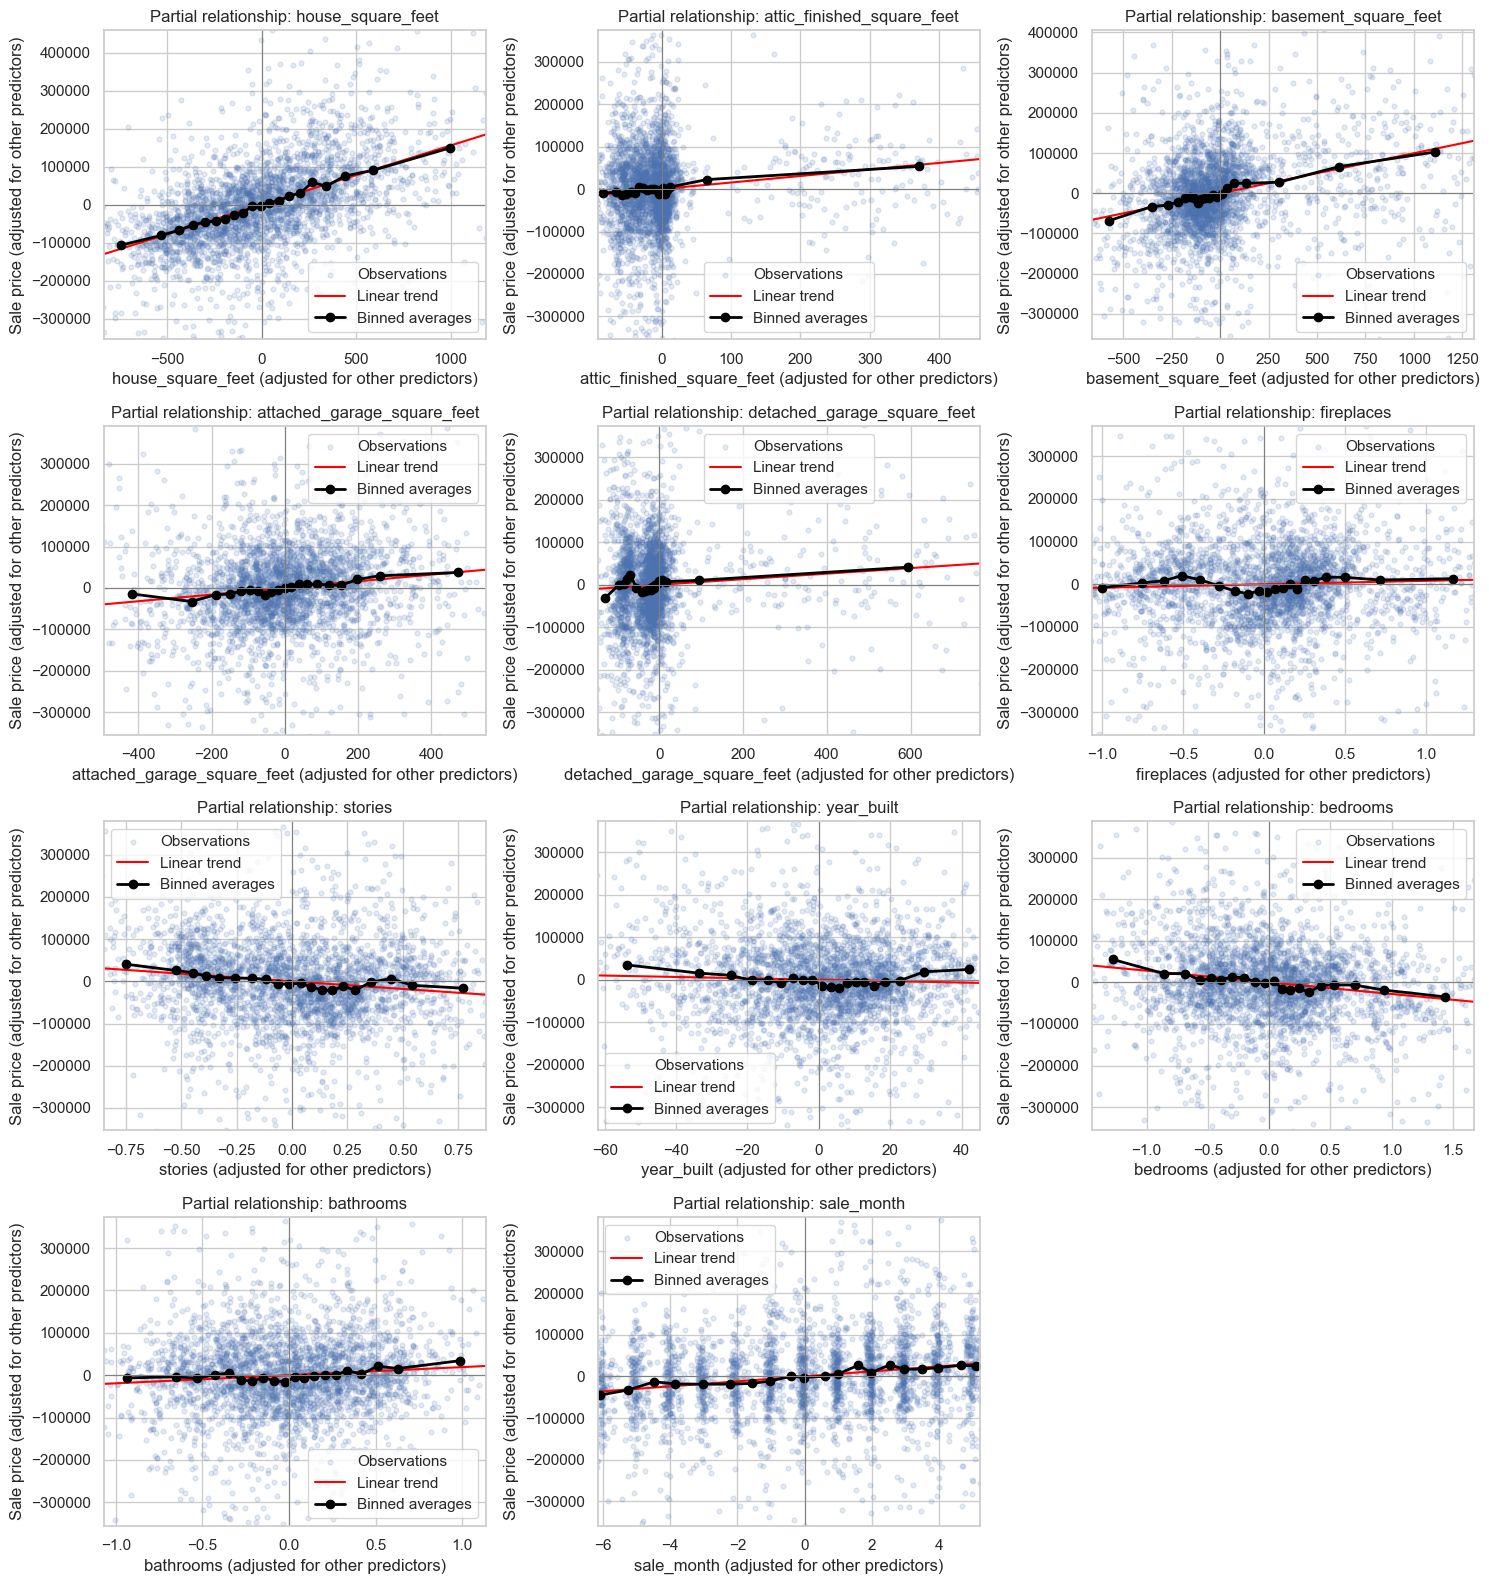

In [ ]:
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import math

numeric_features = [
    "house_square_feet",
    "attic_finished_square_feet",
    "basement_square_feet",
    "attached_garage_square_feet",
    "detached_garage_square_feet",
    "fireplaces",
    "stories",
    "year_built",
    "bedrooms",
    "bathrooms",
    "sale_month",
]

numeric_features = [col for col in numeric_features if col in X_train.columns]
all_features = list(X_train.columns)

ncols = 3
nrows = math.ceil(len(numeric_features) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
axes = np.array(axes).reshape(-1)

for i, feature in enumerate(numeric_features):
    other_features = [col for col in all_features if col != feature]

    y_model = LinearRegression().fit(X_train[other_features], y_train)
    y_residual = y_train - y_model.predict(X_train[other_features])

    x_model = LinearRegression().fit(
        X_train[other_features],
        X_train[feature]
    )
    x_residual = X_train[feature] - x_model.predict(X_train[other_features])

    partial_data = pd.DataFrame({
        "x_residual": np.asarray(x_residual),
        "y_residual": np.asarray(y_residual),
    })

    points = partial_data.sample(
        n=min(3000, len(partial_data)),
        random_state=42
    )
    axes[i].scatter(
        points["x_residual"],
        points["y_residual"],
        alpha=0.15,
        s=12,
        label="Observations"
    )

    x_values = partial_data["x_residual"].to_numpy(dtype=float)
    y_values = partial_data["y_residual"].to_numpy(dtype=float)
    valid = np.isfinite(x_values) & np.isfinite(y_values)
    x_values = x_values[valid]
    y_values = y_values[valid]

    x_scale = max(1.0, np.max(np.abs(x_values))) if len(x_values) else 1.0
    has_variation = (
        len(x_values) > 1
        and np.ptp(x_values) > np.finfo(float).eps * x_scale
    )

    if has_variation:
        slope, intercept = np.polyfit(x_values, y_values, 1)
        x_line = np.linspace(x_values.min(), x_values.max(), 100)
        axes[i].plot(
            x_line,
            slope * x_line + intercept,
            color="red",
            label="Linear trend"
        )

        plot_data = pd.DataFrame({
            "x_residual": x_values,
            "y_residual": y_values
        })
        plot_data["bin"] = pd.qcut(
            plot_data["x_residual"],
            q=20,
            duplicates="drop"
        )
        binned = plot_data.groupby("bin", observed=True).agg(
            x_mean=("x_residual", "mean"),
            y_mean=("y_residual", "mean")
        )
        axes[i].plot(
            binned["x_mean"],
            binned["y_mean"],
            color="black",
            marker="o",
            linewidth=2,
            label="Binned averages"
        )
    else:
        axes[i].text(
            0.5,
            0.95,
            "No variation in adjusted predictor",
            transform=axes[i].transAxes,
            ha="center",
            va="top"
        )
    # Zoom each plot to the middle 98% of points
    if has_variation:
        axes[i].set_xlim(np.percentile(x_values, [1, 99]))
        axes[i].set_ylim(np.percentile(y_values, [1, 99]))

    axes[i].axhline(0, color="gray", linewidth=0.8)
    axes[i].axvline(0, color="gray", linewidth=0.8)
    axes[i].set_title(f"Partial relationship: {feature}")
    axes[i].set_xlabel(f"{feature} (adjusted for other predictors)")
    axes[i].set_ylabel("Sale price (adjusted for other predictors)")
    if has_variation:
        axes[i].legend()

for i in range(len(numeric_features), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()

# Question 6: Build complex model and compare

In [ ]:
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, r2_score

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

view_cols = [c for c in X_train.columns if c.startswith("view_quality_")]
waterfront_cols = [c for c in X_train.columns if c.startswith("waterfront_type_")]

def add_features(X_in):
    Z = X_in.copy()
    # Floor size at 300 sq ft inside the new features
    sqft = Z["house_square_feet"].clip(lower=300)
    # Diminishing returns to size: use log of living area instead of raw square feet
    Z["log_sqft"] = np.log(sqft)
    Z["age"] = 2020 - Z["year_built"]  # every sale is in 2020
    Z["age_sq"] = Z["age"] ** 2
    # Having a basement / attic / garage at all is a step up, separate from its size
    Z["has_basement"] = (Z["basement_square_feet"] > 0).astype(int)
    Z["has_attic"] = (Z["attic_finished_square_feet"] > 0).astype(int)
    Z["has_att_garage"] = (Z["attached_garage_square_feet"] > 0).astype(int)
    Z["has_det_garage"] = (Z["detached_garage_square_feet"] > 0).astype(int)
    # For a given size, more bedrooms means smaller rooms
    Z["beds_per_1000sqft"] = Z["bedrooms"] / sqft * 1000
    # Interactions: views, waterfront, age and bathrooms matter more on bigger houses
    any_view = Z[view_cols].sum(axis=1)
    any_waterfront = Z[waterfront_cols].sum(axis=1)
    Z["log_sqft_x_view"] = Z["log_sqft"] * any_view
    Z["log_sqft_x_waterfront"] = Z["log_sqft"] * any_waterfront
    Z["age_x_log_sqft"] = Z["age"] * Z["log_sqft"]
    Z["baths_x_log_sqft"] = Z["bathrooms"] * Z["log_sqft"]
    # Replaced by log_sqft and age above
    return Z.drop(columns=["house_square_feet", "year_built"])

X_train_c = add_features(X_train)
X_test_c = add_features(X_test)

# Model log(price): features add a percentage to value, and the log evens out the skew
log_y_train = np.log(y_train)
complex_model = LinearRegression().fit(X_train_c, log_y_train)

smear = np.mean(np.exp(log_y_train - complex_model.predict(X_train_c)))
complex_train_pred = np.exp(complex_model.predict(X_train_c)) * smear
complex_test_pred = np.exp(complex_model.predict(X_test_c)) * smear

complex_row = {
    "Model": "Complex (log price, transforms, interactions)",
    "Number of predictors": X_train_c.shape[1],
    "Train RMSE": rmse(y_train, complex_train_pred),
    "Train R²": r2_score(y_train, complex_train_pred),
    "Test RMSE": rmse(y_test, complex_test_pred),
    "Test R²": r2_score(y_test, complex_test_pred),
}
comparison = pd.concat([results_df, pd.DataFrame([complex_row])]).sort_values("Test RMSE")
display(comparison.round(3))

,Model,Number of predictors,Train RMSE,Train R²,Test RMSE,Test R²
3,All predictors (including categories),43,152243.254,0.563,159388.818,0.545
0,"Complex (log price, transforms, interactions)",53,145483.500,0.601,159594.491,0.543
2,All numeric features,11,172606.059,0.438,180557.740,0.416
1,Core features,5,186026.949,0.347,191764.162,0.341
0,House size only,1,193793.719,0.291,198240.046,0.296


In [ ]:
# Dollar RMSE is dominated by a few very expensive sales, so also compare the typical percentage error on the test set
simple_model = LinearRegression().fit(X_train, y_train)
simple_test_pred = simple_model.predict(X_test)

def pct_errors(y_true, y_pred):
    err = np.abs(y_pred - y_true) / y_true
    return {"Median abs. % error": np.median(err),
            "Share within ±10%": np.mean(err <= 0.10),
            "Share within ±20%": np.mean(err <= 0.20)}

display(pd.DataFrame({
    "All predictors (Q4)": pct_errors(y_test, simple_test_pred),
    "Complex (Q6)": pct_errors(y_test, complex_test_pred),
}).T.round(3))

# 5-fold cross-validation on the training set: is the difference consistent?
cv_rows = []
for fold, (tr, va) in enumerate(KFold(5, shuffle=True, random_state=42).split(X_train), start=1):
    m_simple = LinearRegression().fit(X_train.iloc[tr], y_train.iloc[tr])
    m_complex = LinearRegression().fit(X_train_c.iloc[tr], log_y_train.iloc[tr])
    s = np.mean(np.exp(log_y_train.iloc[tr] - m_complex.predict(X_train_c.iloc[tr])))
    cv_rows.append({
        "Fold": fold,
        "All predictors RMSE": rmse(y_train.iloc[va], m_simple.predict(X_train.iloc[va])),
        "Complex RMSE": rmse(y_train.iloc[va], np.exp(m_complex.predict(X_train_c.iloc[va])) * s),
    })
cv_df = pd.DataFrame(cv_rows).set_index("Fold")
cv_df.loc["Mean"] = cv_df.mean()
display(cv_df.round(0))

,Median abs. % error,Share within ±10%,Share within ±20%
All predictors (Q4),0.119,0.431,0.731
Complex (Q6),0.108,0.473,0.758


,All predictors RMSE,Complex RMSE
Fold,,
1,148034.0,140355.0
2,130832.0,127939.0
3,153579.0,145917.0
4,175388.0,174253.0
5,157971.0,144485.0
Mean,153161.0,146590.0


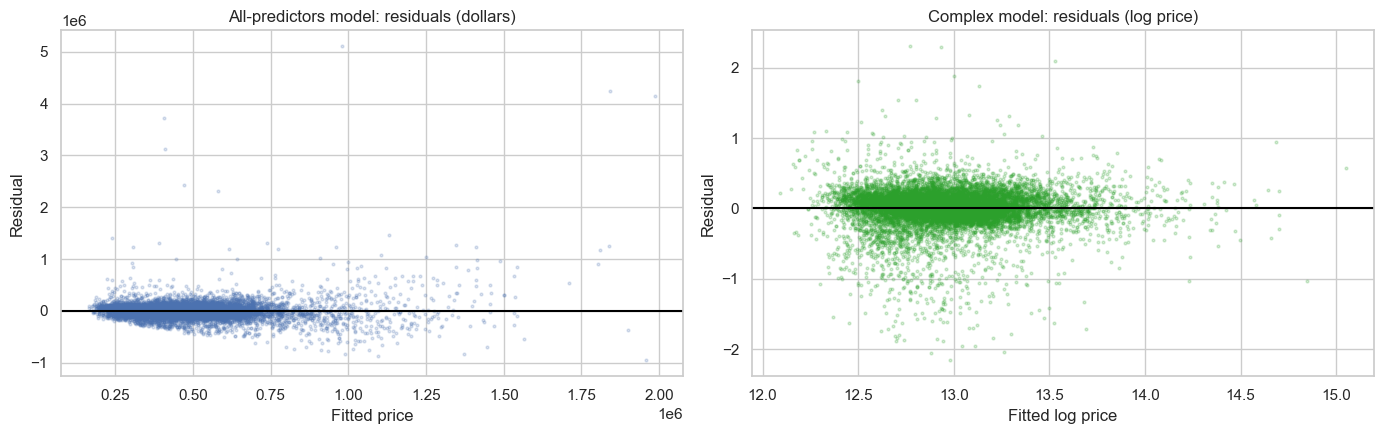

In [ ]:
# Residuals: the dollar model's errors fan out as price grows, the log model's should not
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
simple_fit = simple_model.predict(X_train)
axes[0].scatter(simple_fit, y_train - simple_fit, s=4, alpha=0.2)
axes[0].axhline(0, color="black")
axes[0].set(title="All-predictors model: residuals (dollars)", xlabel="Fitted price", ylabel="Residual")
log_fit = complex_model.predict(X_train_c)
axes[1].scatter(log_fit, log_y_train - log_fit, s=4, alpha=0.2, color="tab:green")
axes[1].axhline(0, color="black")
axes[1].set(title="Complex model: residuals (log price)", xlabel="Fitted log price", ylabel="Residual")
plt.tight_layout()
plt.show()

In [ ]:
# Checking if the bigger train-test gap overfitting or just the split
split_rows = []
for seed in range(20):
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.20, random_state=seed)

    # All-predictors model
    m_simple = LinearRegression().fit(X_tr, y_tr)
    simple_train = rmse(y_tr, m_simple.predict(X_tr))
    simple_test = rmse(y_te, m_simple.predict(X_te))

    # Complex model
    X_tr_c = add_features(X_tr)
    X_te_c = add_features(X_te)
    m_complex = LinearRegression().fit(X_tr_c, np.log(y_tr))
    s = np.mean(np.exp(np.log(y_tr) - m_complex.predict(X_tr_c)))
    complex_train = rmse(y_tr, np.exp(m_complex.predict(X_tr_c)) * s)
    complex_test = rmse(y_te, np.exp(m_complex.predict(X_te_c)) * s)

    split_rows.append({
        "Seed": seed,
        "All predictors test RMSE": simple_test,
        "Complex test RMSE": complex_test,
        "All predictors gap": simple_test - simple_train,
        "Complex gap": complex_test - complex_train,
    })

splits_df = pd.DataFrame(split_rows).set_index("Seed")
wins = (splits_df["Complex test RMSE"] < splits_df["All predictors test RMSE"]).sum()
print("Complex model has lower test RMSE in", wins, "of 20 splits")
display(splits_df.mean().round(0).to_frame("Average over 20 splits"))

Complex model has lower test RMSE in 18 of 20 splits


,Average over 20 splits
All predictors test RMSE,149136.0
Complex test RMSE,143901.0
All predictors gap,-5143.0
Complex gap,-5227.0


We built a more complex model that predicts the log of sale price, since features tend to raise a home's value by a percentage rather than a fixed dollar amount. It uses the log of square footage (each extra square foot adds less in bigger homes), age and age squared (new and historic homes sell for more), flags for having a basement, attic or garage, bedrooms per 1,000 sq ft, and interactions between size and view, waterfront, age and bathrooms. It has a training RMSE of 145,484 dollars (R^2 = 0.601) and a test RMSE of 159,594 dollars (R^2 = 0.543). That is far better than the simpler models (test R^2 of 0.30 for size only, 0.34 for core features and 0.42 for all numeric features), and about tied with the all-predictors model on the test set (159,389 dollars, R^2 = 0.545). The complex model's advantage shows up in cross-validation, where it had lower error in all 5 folds, and in percentage accuracy (10.8% vs. 11.9% median error). Its gap between training and test error is larger, but this comes from our test split being harder rather than overfitting. Over 20 random train/test splits, the complex model had lower test RMSE in 18, and both models had about the same train-test gap.

# Question 7: Summary of Results

Across Questions 1–6, adding information steadily improved the models, with test R^2 rising from 0.30 with house size alone to 0.34 with core features, 0.42 with all numeric features, and 0.545 with all predictors including categories. Cleaning mattered too, since dropping 124 impossible or non-market records raised the all-predictors test R^2 from 0.522 to 0.545. The simple models underfit, since their training and test errors were both high and close together, which means they were missing structure rather than fitting noise. The complex model with log price, transformations and interactions fit the training data better (R^2 0.601) but only tied the all-predictors model on our test set (0.543). Its train–test gap was larger, but across 20 random splits it had lower test error in 18 and about the same gap as the all-predictors model, so it was not overfitting. The main lesson for model selection is that training performance always improves as you add features, so models have to be compared on held-out data. A single test split can also be misleading, because cross-validation showed a real advantage for the complex model that the one test set did not. Finally, about 45% of the variation in price stays unexplained, likely because the data has no location information, which would help more than further complexity.

# Question 8: Regularizing the model and selecting the most predictive features

In [ ]:
from sklearn.linear_model import Lasso, LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Scale features so the penalty is fair, pick alpha with 5-fold CV
lasso_cv = make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=42, max_iter=50_000))
lasso_cv.fit(X_train_c, log_y_train)
best_alpha = lasso_cv[-1].alpha_

# 1-SE rule: bigger alpha, fewer features, about the same CV error
cv_mse = lasso_cv[-1].mse_path_
mse_mean = cv_mse.mean(axis=1)
mse_se = cv_mse.std(axis=1) / np.sqrt(cv_mse.shape[1])
best_i = np.argmin(mse_mean)
alpha_1se = lasso_cv[-1].alphas_[mse_mean <= mse_mean[best_i] + mse_se[best_i]].max()

lasso_rows, lasso_coefs = [], {}
for label, alpha in [("Lasso (best CV alpha)", best_alpha), ("Lasso (1-SE alpha)", alpha_1se)]:
    lasso = make_pipeline(StandardScaler(), Lasso(alpha=alpha, max_iter=50_000)).fit(X_train_c, log_y_train)
    coefs = pd.Series(lasso[-1].coef_, index=X_train_c.columns)
    lasso_coefs[label] = coefs
    s = np.mean(np.exp(log_y_train - lasso.predict(X_train_c)))
    tr_pred = np.exp(lasso.predict(X_train_c)) * s
    te_pred = np.exp(lasso.predict(X_test_c)) * s
    lasso_rows.append({
        "Model": f"{label}, alpha = {alpha:.4f}",
        "Number of predictors": int((coefs != 0).sum()),
        "Train RMSE": rmse(y_train, tr_pred),
        "Train R²": r2_score(y_train, tr_pred),
        "Test RMSE": rmse(y_test, te_pred),
        "Test R²": r2_score(y_test, te_pred),
    })

all_models = pd.concat([comparison, pd.DataFrame(lasso_rows)]).sort_values("Test RMSE")
display(all_models.round(3))

# Features kept vs dropped
for label, coefs in lasso_coefs.items():
    kept = coefs[coefs != 0].sort_values(key=np.abs, ascending=False)
    print(f"\n{label}: keeps {len(kept)} of {len(coefs)} features")
    print("Dropped:", coefs[coefs == 0].index.tolist())

display(lasso_coefs["Lasso (1-SE alpha)"].loc[lambda c: c != 0]
        .sort_values(key=np.abs, ascending=False).round(4)
        .to_frame("Standardized coefficient (1-SE Lasso)"))

,Model,Number of predictors,Train RMSE,Train R²,Test RMSE,Test R²
3,All predictors (including categories),43,152243.254,0.563,159388.818,0.545
0,"Complex (log price, transforms, interactions)",53,145483.500,0.601,159594.491,0.543
0,"Lasso (best CV alpha), alpha = 0.0002",49,145957.605,0.598,160248.781,0.540
1,"Lasso (1-SE alpha), alpha = 0.0068",29,151505.478,0.567,162599.974,0.526
2,All numeric features,11,172606.059,0.438,180557.740,0.416
1,Core features,5,186026.949,0.347,191764.162,0.341
0,House size only,1,193793.719,0.291,198240.046,0.296



Lasso (best CV alpha): keeps 49 of 53 features
Dropped: ['bathrooms', 'exterior_Masonry Concrete Block', 'age', 'log_sqft_x_view']

Lasso (1-SE alpha): keeps 29 of 53 features
Dropped: ['bedrooms', 'bathrooms', 'hvac_description_Floor/Wall Furnace', 'hvac_description_Forced Air', 'hvac_description_Hot Water Baseboard', 'hvac_description_No Heat', 'exterior_Masonry Common Brick', 'exterior_Masonry Concrete Block', 'interior_Other', 'roof_cover_Formed Seam Metal', 'roof_cover_Other', 'roof_cover_Preformed Metal', 'roof_cover_Wood Shake', 'waterfront_type_WF River', 'waterfront_type_WF Stream/Creek', 'view_quality_View Avg', 'view_quality_View Good', 'view_quality_View Lim', 'view_quality_View Lim +', 'view_quality_View Lim -', 'utility_sewer_SEWER/SEPTIC INSTALLED', 'age', 'age_sq', 'has_det_garage']


,Standardized coefficient (1-SE Lasso)
log_sqft,0.1518
waterfront_type_WF Salt,0.0606
basement_square_feet,0.0496
attached_garage_square_feet,0.0480
baths_x_log_sqft,0.0407
waterfront_type_WF Lake,0.0397
log_sqft_x_view,0.0367
sale_month,0.0364
hvac_description_Heat Pump,0.0236
beds_per_1000sqft,-0.0221


Using the Lasso on the complex model's standardized features, with alpha chosen by 5-fold cross-validation (about 0.0002), keeps 49 of 53 features. It drops only bathrooms, age, Masonry Concrete Block exterior and the view × size interaction. It has a training RMSE of 145,958 dollars (R^2 = 0.598) and a test RMSE of 160,249 dollars (R^2 = 0.540), about the same as the complex model. A stronger alpha (about 0.0068, 1-SE rule) keeps only 29 features, led by log living area, salt-water and lake frontage, basement and garage size, bathrooms × size, view × size and sale month, with a test RMSE of 162,600 dollars (R^2 = 0.526). The Lasso didn't improve accuracy, but it gave a much simpler model that predicts almost as well.

### *Reflection on AI assistance
In your own words without generative AI.

The main improvements we made with GPT-6's help were updating our overfitting claim and clarifying the multi-row sales issue in Q1. The complex model performed better in 18 of 20 random splits, with similar train-test gaps between both models. The cross-validation RMSE was also close to the training RMSE, at 146.6K dollars compared to 145.5K, suggesting that overfitting was not an issue. We also clarified that some properties had multiple rows with the same full sale price, which could appear in both training and test sets. Some suggestions turned out to be incorrect after rerunning the code. Adding sale-month variables slightly worsened RMSE, and the supposed contradiction between Q1 and Q5 about year built wasn't an issue. We also decided against removing multi-row sales because many of the 3,307 rows matching by date and price did so by coincidence. To verify the suggested changes, we reran the notebook without errors, tested 20 random splits, and manually checked the 6.13M and 6.09M dollar sales. We still have some concerns, such as the pre-cleaning test R^2 of 0.522 not being reproducible, as the rerun gave 0.532. Multi-building sales remain, and around 45% of price variation is unexplained, potentially due to missing location data.